In [1]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('ShopSmart_synthetic_50000.csv')

In [4]:
df.sample(10)

,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used,Amount_Spent
21735,49,456181.0,6.0,11,Bronze,Electronics,Tier 3,Yes,15766.50
32730,48,596781.0,8.0,5,Bronze,Home,Tier 1,Yes,15005.76
8228,32,800169.0,7.0,8,Bronze,Beauty,Tier 3,Yes,13954.62
18304,63,445931.0,11.0,9,Silver,Beauty,Tier 1,Yes,17310.08
48666,64,645870.0,16.0,8,Silver,Fashion,Tier 3,No,17622.09
18790,40,751811.0,17.0,14,Gold,Beauty,Tier 3,No,20483.09
14190,52,1057365.0,15.0,1,Silver,Home,Tier 2,Yes,19454.42
11259,19,944993.0,13.0,4,Silver,Home,Tier 2,Yes,18058.46
3821,43,790978.0,8.0,6,Bronze,Fashion,Tier 1,Yes,16798.79
14313,55,494456.0,8.0,11,Bronze,Electronics,Tier 3,No,15277.97


In [6]:
df.isnull().sum()

,0
Age,0
Annual_Income,437
Website_Visits,403
Previous_Purchases,0
Membership_Type,414
Preferred_Category,388
City_Tier,0
Discount_Used,0
Amount_Spent,0


In [8]:
# Impute missing values based on specified strategies
df['Annual_Income'] = df['Annual_Income'].fillna(df['Annual_Income'].median())
df['Website_Visits'] = df['Website_Visits'].fillna(df['Website_Visits'].mean())
df['Membership_Type'] = df['Membership_Type'].fillna(df['Membership_Type'].mode()[0])
df['Preferred_Category'] = df['Preferred_Category'].fillna(df['Preferred_Category'].mode()[0])

# Verify if any missing values remain
df.isnull().sum()

,0
Age,0
Annual_Income,0
Website_Visits,0
Previous_Purchases,0
Membership_Type,0
Preferred_Category,0
City_Tier,0
Discount_Used,0
Amount_Spent,0


In [9]:
# Create 5 bin ranges for 'Amount_Spent' using quantiles
df['Amount_Spent_Range'] = pd.qcut(df['Amount_Spent'], q=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])

# Display some sample rows to verify the new column and check distribution
print(df['Amount_Spent_Range'].value_value_counts() if hasattr(df['Amount_Spent_Range'], 'value_value_counts') else df['Amount_Spent_Range'].value_counts())
display(df[['Amount_Spent', 'Amount_Spent_Range']].head(10))

Amount_Spent_Range
Very Low     10000
Low          10000
Medium       10000
High         10000
Very High    10000
Name: count, dtype: int64


,Amount_Spent,Amount_Spent_Range
0,21323.29,Very High
1,16160.83,Low
2,10315.23,Very Low
3,16518.29,Low
4,17816.27,Medium
5,22063.24,Very High
6,15606.70,Low
7,16726.71,Medium
8,16332.97,Low
9,18048.73,Medium


In [18]:
# Define the bins and labels for the age groups
bins = [-float('inf'), 19, 30, 40, 50, 70, float('inf')]
labels = ['Below 20', '20-30', '30-40', '40-50', '50-70', '70+']

# Create the Age_Group column
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

# Display the counts of each group to verify the result
print(df['Age_Group'].value_counts().sort_index())

# Show a preview of the dataset with the new column
df[['Age', 'Age_Group']].head(10)

Age_Group
Below 20     2415
20-30        7986
30-40       13901
40-50       14268
50-70       11430
70+             0
Name: count, dtype: int64


,Age,Age_Group
0,41,40-50
1,58,50-70
2,57,50-70
3,34,30-40
4,37,30-40
5,34,30-40
6,48,40-50
7,40,30-40
8,50,40-50
9,18,Below 20


In [11]:
# Calculate the min and max numeric values for each Amount_Spent_Range
df.groupby('Amount_Spent_Range', observed=False)['Amount_Spent'].agg(['min', 'max'])

,min,max
Amount_Spent_Range,,
Very Low,6000.00,14320.17
Low,14320.34,16531.70
Medium,16532.39,18478.84
High,18478.92,20733.25
Very High,20733.54,34139.26


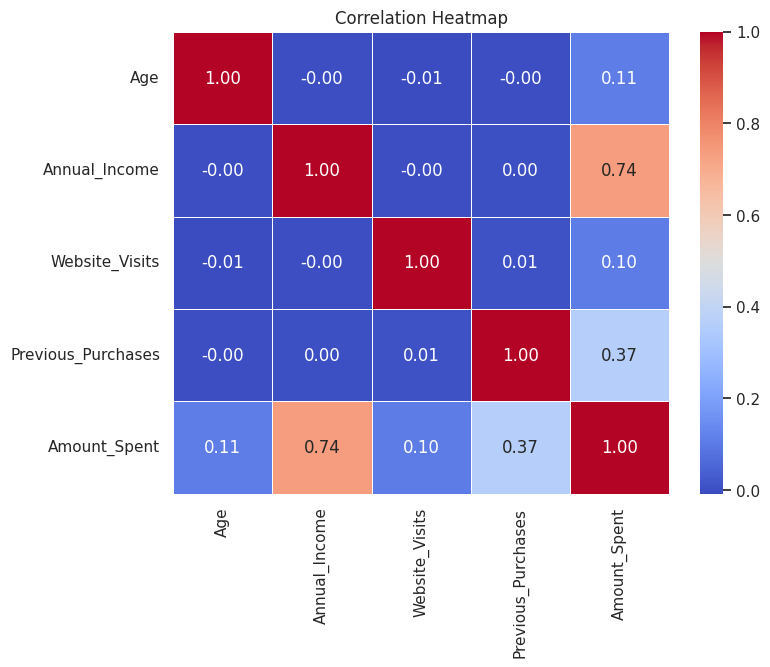

,Age,Annual_Income,Website_Visits,Previous_Purchases,Amount_Spent
Age,1.000000,-0.001594,-0.008202,-0.002781,0.109774
Annual_Income,-0.001594,1.000000,-0.000647,0.001464,0.736704
Website_Visits,-0.008202,-0.000647,1.000000,0.007322,0.103380
Previous_Purchases,-0.002781,0.001464,0.007322,1.000000,0.365687
Amount_Spent,0.109774,0.736704,0.103380,0.365687,1.000000


In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numerical columns for correlation analysis
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Calculate correlation matrix
corr_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

# Display the correlation matrix values
corr_matrix

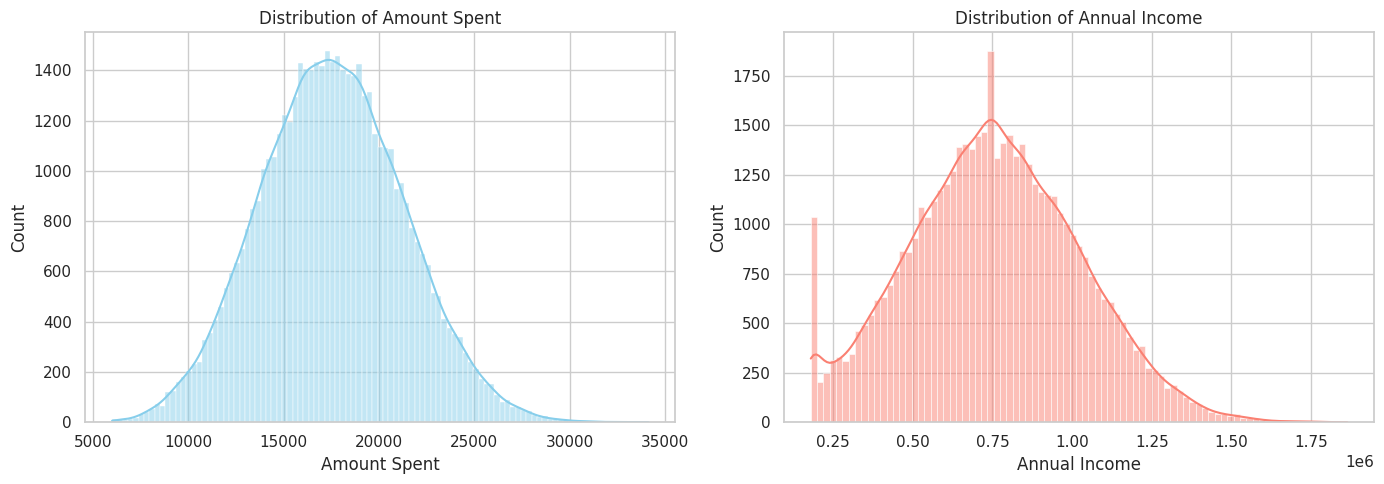

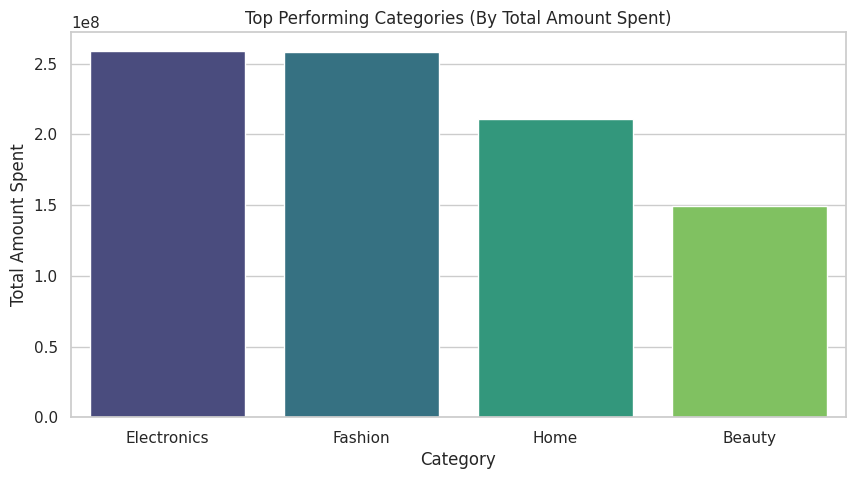

,Preferred_Category,sum,mean
1,Electronics,2.591389e+08,18700.940377
2,Fashion,2.581791e+08,17014.569870
3,Home,2.108547e+08,17690.638590
0,Beauty,1.494799e+08,16517.111770


In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set up the visualization style
sns.set_theme(style="whitegrid")

# 1. Distribution Curves (KDE) for continuous columns: Annual_Income and Amount_Spent
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Amount_Spent'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Amount Spent')
axes[0].set_xlabel('Amount Spent')

sns.histplot(df['Annual_Income'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Annual Income')
axes[1].set_xlabel('Annual Income')

plt.tight_layout()
plt.show()

# 2. Top Performing Categories based on Total Amount Spent
category_performance = df.groupby('Preferred_Category')['Amount_Spent'].agg(['sum', 'mean']).reset_index()
category_performance = category_performance.sort_values(by='sum', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=category_performance, x='Preferred_Category', y='sum', palette='viridis', hue='Preferred_Category', legend=False)
plt.title('Top Performing Categories (By Total Amount Spent)')
plt.xlabel('Category')
plt.ylabel('Total Amount Spent')
plt.show()

category_performance

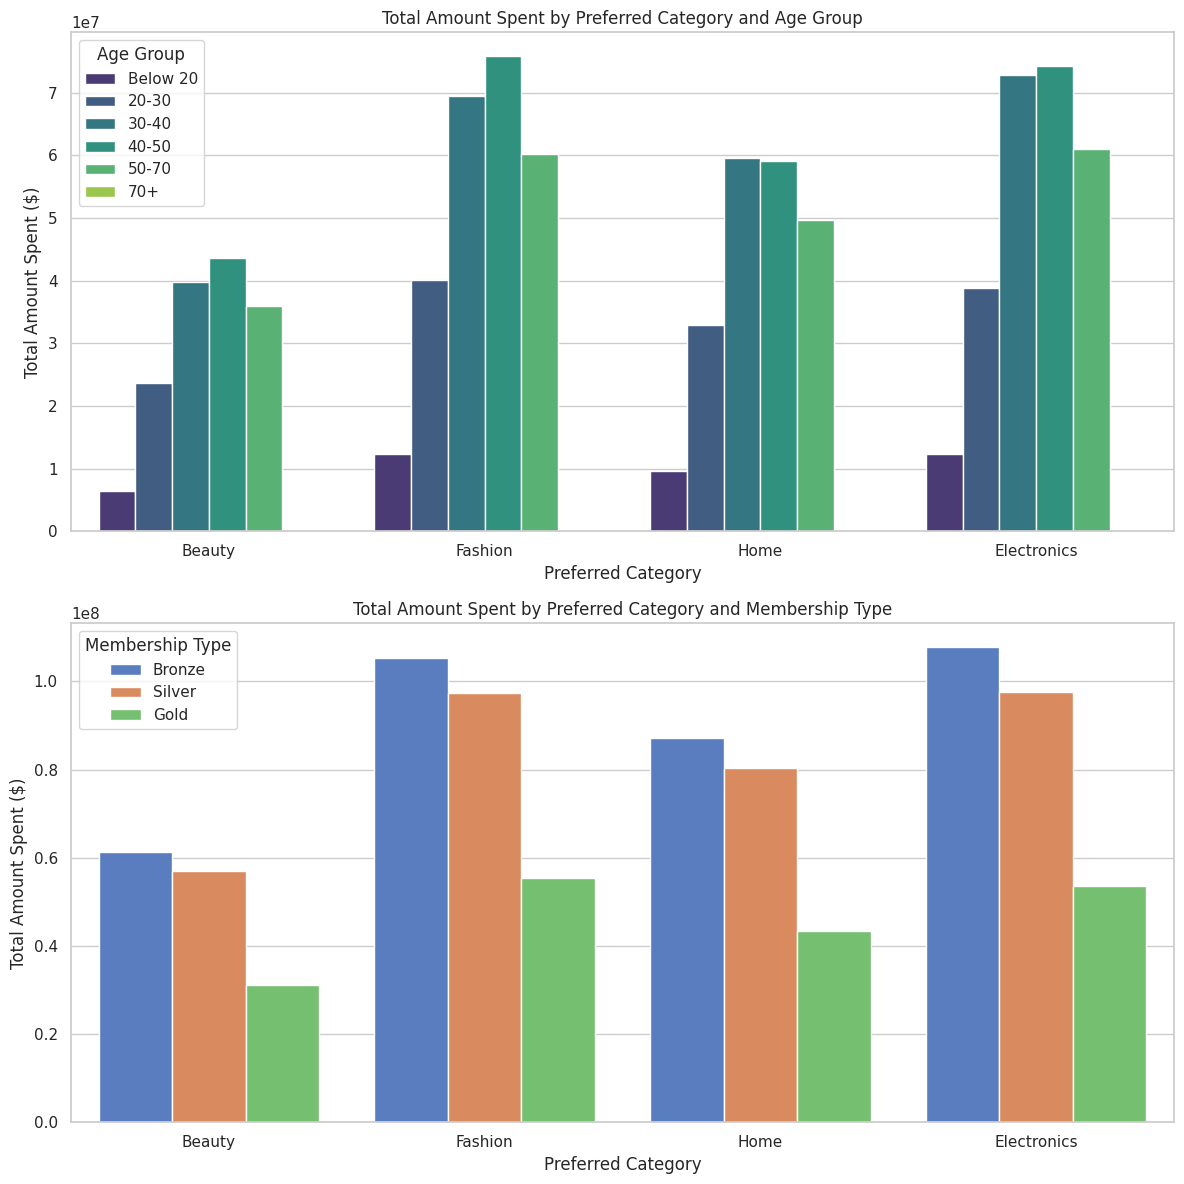

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the styling
sns.set_theme(style="whitegrid")

# Create a multi-plot layout
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

# 1. Bar Graph: Category vs Age Group
sns.barplot(
    data=df,
    x='Preferred_Category',
    y='Amount_Spent',
    hue='Age_Group',
    estimator=sum,
    errorbar=None,
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Total Amount Spent by Preferred Category and Age Group')
axes[0].set_xlabel('Preferred Category')
axes[0].set_ylabel('Total Amount Spent ($)')
axes[0].legend(title='Age Group')

# 2. Bar Graph: Category vs Membership Type
sns.barplot(
    data=df,
    x='Preferred_Category',
    y='Amount_Spent',
    hue='Membership_Type',
    estimator=sum,
    errorbar=None,
    palette='muted',
    ax=axes[1]
)
axes[1].set_title('Total Amount Spent by Preferred Category and Membership Type')
axes[1].set_xlabel('Preferred Category')
axes[1].set_ylabel('Total Amount Spent ($)')
axes[1].legend(title='Membership Type')

plt.tight_layout()
plt.show()

In [24]:
import os

# Export the cleaned DataFrame to a new CSV file
export_filename = 'ShopSmart_synthetic_cleaned.csv'
df.to_csv(export_filename, index=False)

# Confirm that the file has been successfully written
if os.path.exists(export_filename):
    print(f"Successfully exported cleaned dataset to: {export_filename}")
    print(f"File size: {os.path.getsize(export_filename) / (1024 * 1024):.2f} MB")
else:
    print("Failed to export the dataset.")

Successfully exported cleaned dataset to: ShopSmart_synthetic_cleaned.csv
File size: 3.17 MB
